In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:

import matplotlib.pyplot as plt

In [4]:
print("hi")

hi


In [6]:
df=pd.read_csv("../car_data_messy.csv")

In [7]:
df

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
0,CAR1032,Volkswagen Polo GT,2020,714379 INR,50290.0,CNG,Individual,Manual,First Owner,showroom serviced
1,CAR1036,Maruti 800 AC,2011,%469331,48141.0,Diesel,Dealer,Manual,First Owner,good condition
2,CAR1001,Toyota Innova 2.5,2010,%381458,137164.0,Diesel,Individual,Manual,Second Owner,NaN
3,CAR1018,Toyota Innova 2.5,2019,$687035,93754.0,Diesel,Individual,Manual,First Owner,showroom serviced
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,NaN,Individual,Automatic,Second Owner,single owner
...,...,...,...,...,...,...,...,...,...,...
70,CAR1043,Maruti Wagon R LXI,2004,"239,205",110382.0,Diesel,Dealer,Manual,Second Owner,showroom serviced
71,CAR1022,Maruti Alto LXI,2020,%631856,116086.0,Petrol,Individual,Manual,Second Owner,good condition
72,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Petrol,Dealer,Manual,Second Owner,NaN
73,CAR1015,Hyundai Creta 1.6,2014,$393079,140324.0,Petrol,Dealer,Manual,First Owner,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_id         75 non-null     str    
 1   name           75 non-null     str    
 2   year           75 non-null     int64  
 3   selling_price  73 non-null     str    
 4   km_driven      72 non-null     float64
 5   fuel           71 non-null     str    
 6   seller_type    75 non-null     str    
 7   transmission   75 non-null     str    
 8   owner          71 non-null     str    
 9   notes          49 non-null     str    
dtypes: float64(1), int64(1), str(8)
memory usage: 11.4 KB


In [9]:
df.isna().sum()
# null count

car_id            0
name              0
year              0
selling_price     2
km_driven         3
fuel              4
seller_type       0
transmission      0
owner             4
notes            26
dtype: int64

In [10]:
df['km_driven']

0      50290.0
1      48141.0
2     137164.0
3      93754.0
4      60432.0
        ...   
70    110382.0
71    116086.0
72      9730.0
73    140324.0
74     71766.0
Name: km_driven, Length: 75, dtype: float64

In [11]:
df['km_driven'].describe()

count        72.000000
mean      79442.402778
std       41801.616125
min        9255.000000
25%       48055.750000
50%       73639.000000
75%      114767.500000
max      149832.000000
Name: km_driven, dtype: float64

In [12]:
df['km_driven'].median()

np.float64(73639.0)

In [13]:
#filling the nan values
df['km_driven'] = df['km_driven'].fillna(df['km_driven'].median())

In [14]:
df['km_driven'].isna().sum()

np.int64(0)

In [15]:
type(df)

pandas.DataFrame

In [17]:
df[df['fuel'].isna()==1]

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,NaN,Individual,Automatic,Second Owner,single owner
20,CAR1041,Hyundai Verna 1.6 SX,2015,$589041,42393.0,NaN,Dealer,Manual,First Owner,showroom serviced
23,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,NaN,Individual,Automatic,Second Owner,single owner
47,CAR1057,Maruti Wagon R LXI,2018,685999,21194.0,NaN,Individual,Manual,First Owner,NaN


In [18]:
df['fuel'].value_counts()

fuel
Petrol    40
Diesel    24
CNG        5
LPG        2
Name: count, dtype: int64

In [19]:
df['fuel']=df['fuel'].fillna(df['fuel'].mode()[0])
print("hi")

hi


In [34]:
df['fuel'].isna().sum()

np.int64(0)

In [35]:
df['selling_price'].unique()

<ArrowStringArray>
['714379 INR',    '%469331',    '%381458',    '$687035',     '689804',
     '303008',     '258274',     '222837',    '$531580',    '754,939',
     '270667',     '520474',    '%436507',          nan,     '593497',
 '404934 INR',     '343434',    '616,669',     '629802',    '$320830',
    '$589041',    '%465041',    '$527257', '342562 INR',     '245489',
    '%324575',     '536392',    '$403045',     '309234',    '$335401',
    '487,985',     '284947',    '$198567',     '368081',     '608444',
 '593484 INR',     '690697', '335218 INR',     '534075',     '609005',
    '$853450',    '$527894',     '437676',     '471797',    '$163438',
     '685999',     '737107',     '220024',     '365352',     '606766',
    '$373083',    '%207557',    '%448513', '261246 INR',    '%599906',
     '143460',    '$678209',     '485394',    '$583558', '484496 INR',
     '568798',    '%647863',     '504727',     '347792',    '446,909',
    '239,205',    '%631856',    '$393079', '297673 INR']
L

In [36]:
df['selling_price'] = df['selling_price'].str.replace('INR', '', regex=False)
df['selling_price'] = df['selling_price'].str.replace('%', '', regex=False)
df['selling_price'] = df['selling_price'].str.replace('$', '', regex=False)
df['selling_price'] = df['selling_price'].str.replace(',', '', regex=False)

In [37]:
df['selling_price'].unique()

<ArrowStringArray>
['714379 ',  '469331',  '381458',  '687035',  '689804',  '303008',  '258274',
  '222837',  '531580',  '754939',  '270667',  '520474',  '436507',       nan,
  '593497', '404934 ',  '343434',  '616669',  '629802',  '320830',  '589041',
  '465041',  '527257', '342562 ',  '245489',  '324575',  '536392',  '403045',
  '309234',  '335401',  '487985',  '284947',  '198567',  '368081',  '608444',
 '593484 ',  '690697', '335218 ',  '534075',  '609005',  '853450',  '527894',
  '437676',  '471797',  '163438',  '685999',  '737107',  '220024',  '365352',
  '606766',  '373083',  '207557',  '448513', '261246 ',  '599906',  '143460',
  '678209',  '485394',  '583558', '484496 ',  '568798',  '647863',  '504727',
  '347792',  '446909',  '239205',  '631856',  '393079', '297673 ']
Length: 69, dtype: str

In [38]:
#nan to '0' to conver it 
df['selling_price'] = df['selling_price'].fillna('0')

In [39]:
df['selling_price'].isna().sum()

np.int64(0)

In [99]:
df['selling_price'] = df['selling_price'].astype('int64')

In [100]:
df.isna().sum()

car_id            0
name              0
year              0
selling_price     0
km_driven         0
fuel              0
seller_type       0
transmission      0
owner             4
notes            26
dtype: int64

In [103]:
df.duplicated().sum()

np.int64(5)

In [107]:
#df[df.duplicated()==1]
df[df['car_id'].duplicated()==1]

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
23,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Petrol,Individual,Automatic,Second Owner,single owner
49,CAR1054,Toyota Innova 2.5,2004,198567,94560.0,Petrol,Individual,Manual,First Owner,good condition
53,CAR1065,Ford Figo Titanium,2010,368081,78227.0,Petrol,Dealer,Manual,Third Owner,showroom serviced
63,CAR1026,Volkswagen Polo GT,2006,324575,64587.0,Petrol,Individual,Automatic,First Owner,single owner
72,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Petrol,Dealer,Manual,Second Owner,NaN


In [108]:
df[df['car_id'].duplicated(keep=False)].sort_values('car_id')

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
26,CAR1026,Volkswagen Polo GT,2006,324575,64587.0,Petrol,Individual,Automatic,First Owner,single owner
63,CAR1026,Volkswagen Polo GT,2006,324575,64587.0,Petrol,Individual,Automatic,First Owner,single owner
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Petrol,Individual,Automatic,Second Owner,single owner
23,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Petrol,Individual,Automatic,Second Owner,single owner
34,CAR1054,Toyota Innova 2.5,2004,198567,94560.0,Petrol,Individual,Manual,First Owner,good condition
49,CAR1054,Toyota Innova 2.5,2004,198567,94560.0,Petrol,Individual,Manual,First Owner,good condition
35,CAR1065,Ford Figo Titanium,2010,368081,78227.0,Petrol,Dealer,Manual,Third Owner,showroom serviced
53,CAR1065,Ford Figo Titanium,2010,368081,78227.0,Petrol,Dealer,Manual,Third Owner,showroom serviced
5,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Petrol,Dealer,Manual,Second Owner,NaN
72,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Petrol,Dealer,Manual,Second Owner,NaN


In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_id         75 non-null     str    
 1   name           75 non-null     str    
 2   year           75 non-null     int64  
 3   selling_price  75 non-null     int64  
 4   km_driven      75 non-null     float64
 5   fuel           75 non-null     str    
 6   seller_type    75 non-null     str    
 7   transmission   75 non-null     str    
 8   owner          71 non-null     str    
 9   notes          49 non-null     str    
dtypes: float64(1), int64(2), str(7)
memory usage: 10.9 KB


In [110]:
df['owner'] = df['owner'].fillna(df['owner'].mode()[0])

In [111]:
df['notes'] = df['notes'].fillna('no notes')

In [112]:
df.isna().sum()

car_id           0
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
notes            0
dtype: int64

In [113]:
df.drop_duplicates()

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
0,CAR1032,Volkswagen Polo GT,2020,714379,50290.0,CNG,Individual,Manual,First Owner,showroom serviced
1,CAR1036,Maruti 800 AC,2011,469331,48141.0,Diesel,Dealer,Manual,First Owner,good condition
2,CAR1001,Toyota Innova 2.5,2010,381458,137164.0,Diesel,Individual,Manual,Second Owner,no notes
3,CAR1018,Toyota Innova 2.5,2019,687035,93754.0,Diesel,Individual,Manual,First Owner,showroom serviced
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Petrol,Individual,Automatic,Second Owner,single owner
...,...,...,...,...,...,...,...,...,...,...
69,CAR1007,Renault Duster RXL,2007,446909,47800.0,Diesel,Individual,Automatic,Fourth & Above Owner,single owner
70,CAR1043,Maruti Wagon R LXI,2004,239205,110382.0,Diesel,Dealer,Manual,Second Owner,showroom serviced
71,CAR1022,Maruti Alto LXI,2020,631856,116086.0,Petrol,Individual,Manual,Second Owner,good condition
73,CAR1015,Hyundai Creta 1.6,2014,393079,140324.0,Petrol,Dealer,Manual,First Owner,no notes


In [114]:
df

,car_id,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,notes
0,CAR1032,Volkswagen Polo GT,2020,714379,50290.0,CNG,Individual,Manual,First Owner,showroom serviced
1,CAR1036,Maruti 800 AC,2011,469331,48141.0,Diesel,Dealer,Manual,First Owner,good condition
2,CAR1001,Toyota Innova 2.5,2010,381458,137164.0,Diesel,Individual,Manual,Second Owner,no notes
3,CAR1018,Toyota Innova 2.5,2019,687035,93754.0,Diesel,Individual,Manual,First Owner,showroom serviced
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Petrol,Individual,Automatic,Second Owner,single owner
...,...,...,...,...,...,...,...,...,...,...
70,CAR1043,Maruti Wagon R LXI,2004,239205,110382.0,Diesel,Dealer,Manual,Second Owner,showroom serviced
71,CAR1022,Maruti Alto LXI,2020,631856,116086.0,Petrol,Individual,Manual,Second Owner,good condition
72,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Petrol,Dealer,Manual,Second Owner,no notes
73,CAR1015,Hyundai Creta 1.6,2014,393079,140324.0,Petrol,Dealer,Manual,First Owner,no notes


In [115]:
#linear regression
import seaborn as sns

In [116]:
import matplotlib.pyplot as plt

In [124]:
df[['year', 'selling_price']].cov()

,year,selling_price
year,26.748468,7.909664e+05
selling_price,790966.361081,3.286113e+10


In [125]:
df[['year', 'selling_price']].corr()

,year,selling_price
year,1.00000,0.84366
selling_price,0.84366,1.00000


In [126]:
# Encode categorical columns into numeric 0/1 columns
df_encoded = pd.get_dummies(df, columns=['fuel', 'owner'], drop_first=True)

In [130]:
df_encoded

,car_id,name,year,selling_price,km_driven,seller_type,transmission,notes,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_Fourth & Above Owner,owner_Second Owner,owner_Third Owner
0,CAR1032,Volkswagen Polo GT,2020,714379,50290.0,Individual,Manual,showroom serviced,False,False,False,False,False,False
1,CAR1036,Maruti 800 AC,2011,469331,48141.0,Dealer,Manual,good condition,True,False,False,False,False,False
2,CAR1001,Toyota Innova 2.5,2010,381458,137164.0,Individual,Manual,no notes,True,False,False,False,True,False
3,CAR1018,Toyota Innova 2.5,2019,687035,93754.0,Individual,Manual,showroom serviced,True,False,False,False,False,False
4,CAR1027,Hyundai Verna 1.6 SX,2019,689804,60432.0,Individual,Automatic,single owner,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,CAR1043,Maruti Wagon R LXI,2004,239205,110382.0,Dealer,Manual,showroom serviced,True,False,False,False,True,False
71,CAR1022,Maruti Alto LXI,2020,631856,116086.0,Individual,Manual,good condition,False,False,True,False,True,False
72,CAR1066,Mahindra XUV500 W8,2006,303008,9730.0,Dealer,Manual,no notes,False,False,True,False,True,False
73,CAR1015,Hyundai Creta 1.6,2014,393079,140324.0,Dealer,Manual,no notes,False,False,True,False,False,False


In [131]:
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

Original shape: (75, 10)
Encoded shape: (75, 14)


In [132]:
df_encoded.columns

Index(['car_id', 'name', 'year', 'selling_price', 'km_driven', 'seller_type',
       'transmission', 'notes', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol',
       'owner_Fourth & Above Owner', 'owner_Second Owner',
       'owner_Third Owner'],
      dtype='str')

In [138]:
    # Correlation matrix including encoded fuel & owner columns
    numeric_cols = ['year', 'selling_price', 'km_driven'] + \
        [col for col in df_encoded.columns if c
                ol.startswith('fuel_') or col.startswith('owner_')]
    
    corr = df_encoded[numeric_cols].corr()
    
    corr

,year,selling_price,km_driven,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_Fourth & Above Owner,owner_Second Owner,owner_Third Owner
year,1.000000,0.843660,-0.001092,0.002671,-0.058425,-0.072664,0.153107,-0.109871,0.039415
selling_price,0.843660,1.000000,-0.270041,0.038237,-0.085688,-0.110849,0.196614,-0.024647,0.013459
km_driven,-0.001092,-0.270041,1.000000,0.212440,-0.022648,-0.127077,0.000015,-0.056927,-0.017600
fuel_Diesel,0.002671,0.038237,0.212440,1.000000,-0.113547,-0.817271,0.005835,0.040841,-0.096930
fuel_LPG,-0.058425,-0.085688,-0.022648,-0.113547,1.000000,-0.197196,-0.033787,-0.120571,-0.048810
fuel_Petrol,-0.072664,-0.110849,-0.127077,-0.817271,-0.197196,1.000000,-0.105012,0.042481,0.147712
owner_Fourth & Above Owner,0.153107,0.196614,0.000015,0.005835,-0.033787,-0.105012,1.000000,-0.148690,-0.060193
owner_Second Owner,-0.109871,-0.024647,-0.056927,0.040841,-0.120571,0.042481,-0.148690,1.000000,-0.214803
owner_Third Owner,0.039415,0.013459,-0.017600,-0.096930,-0.048810,0.147712,-0.060193,-0.214803,1.000000


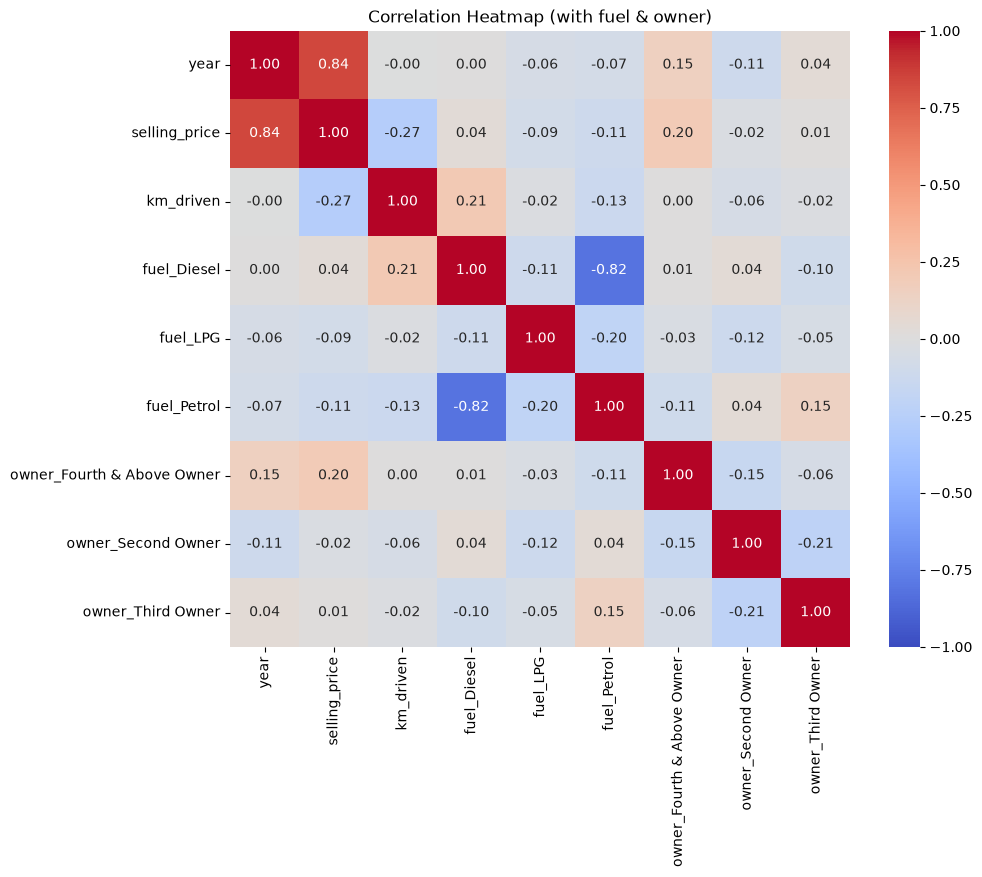

In [139]:
# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (with fuel & owner)")
plt.show()

In [141]:

# train_test_split -> splits our data into training and testing sets
from sklearn.model_selection import train_test_split

# LinearRegression -> the machine learning model we will use
from sklearn.linear_model import LinearRegression

# metrics -> to check how good our model's predictions are
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [142]:
X = df_encoded.drop(columns=['car_id', 'name', 'notes', 'selling_price'])
y = df_encoded['selling_price']

In [ ]:
# Correlation with target only, sorted — easiest way to spot weak features
corr['selling_price'].sort_values(ascending=False)

In [ ]:
# Correlation with target only, sorted — easiest way to spot weak features
corr['selling_price'].sort_values(ascending=False)